In [0]:

WITH purchases_by_customer AS (
    SELECT
        dc.customer_unique_id,
        COUNT(DISTINCT fs.order_id) AS total_pedidos
    FROM olist_dw.dw.fact_sales fs
    INNER JOIN olist_dw.dw.dim_customer dc
        ON fs.customer_sk = dc.customer_sk
    GROUP BY dc.customer_unique_id
)

SELECT
    COUNT(*) AS total_clientes,
    SUM(
        CASE WHEN total_pedidos > 1 THEN 1 ELSE 0 END
    ) AS clientes_recorrentes,
    ROUND(
        100.0 * SUM(
            CASE WHEN total_pedidos > 1 THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS percentual_clientes_recorrentes
FROM purchases_by_customer;


total_clientes,clientes_recorrentes,percentual_clientes_recorrentes
95420,2913,3.05


In [0]:

SELECT
    payment_type AS meio_pagamento,
    COUNT(*) AS quantidade_pagamentos,
    COUNT(DISTINCT order_id) AS quantidade_pedidos,
    ROUND(SUM(payment_value), 2) AS valor_total,
    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
        2
    ) AS percentual_pagamentos
FROM olist_dw.dw.fact_payments
GROUP BY payment_type
ORDER BY quantidade_pagamentos DESC;


meio_pagamento,quantidade_pagamentos,quantidade_pedidos,valor_total,percentual_pagamentos
credit_card,76795,76505,1.254208419E7,73.92
boleto,19784,19784,2869361.27,19.04
voucher,5775,3866,379436.87,5.56
debit_card,1529,1528,217989.79,1.47
not_defined,3,3,0.0,0.00


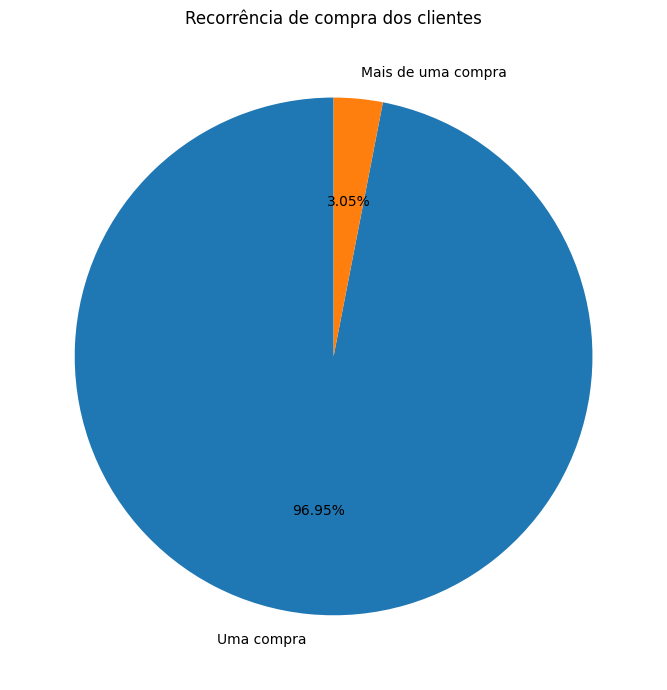

In [0]:
%python

import matplotlib.pyplot as plt

df_recurrence = spark.sql("""
    WITH purchases_by_customer AS (
        SELECT
            dc.customer_unique_id,
            COUNT(DISTINCT fs.order_id) AS total_pedidos
        FROM olist_dw.dw.fact_sales fs
        INNER JOIN olist_dw.dw.dim_customer dc
            ON fs.customer_sk = dc.customer_sk
        GROUP BY dc.customer_unique_id
    )
    SELECT
        CASE
            WHEN total_pedidos > 1 THEN 'Mais de uma compra'
            ELSE 'Uma compra'
        END AS tipo_cliente,
        COUNT(*) AS quantidade
    FROM purchases_by_customer
    GROUP BY 1
""").toPandas()

plt.figure(figsize=(8, 7))
plt.pie(
    df_recurrence["quantidade"],
    labels=df_recurrence["tipo_cliente"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Recorrência de compra dos clientes")
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/recorrencia_clientes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


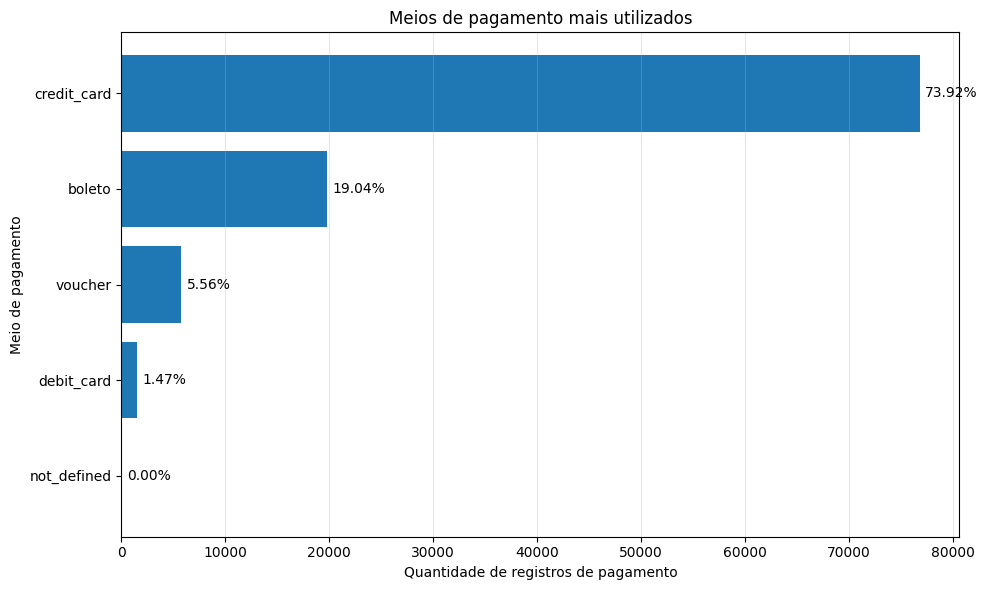

In [0]:
%python

import matplotlib.pyplot as plt

df_payments = spark.sql("""
    SELECT
        payment_type AS meio_pagamento,
        COUNT(*) AS quantidade_pagamentos,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentual
    FROM olist_dw.dw.fact_payments
    GROUP BY payment_type
    ORDER BY quantidade_pagamentos
""").toPandas()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    df_payments["meio_pagamento"],
    df_payments["quantidade_pagamentos"]
)

plt.title("Meios de pagamento mais utilizados")
plt.xlabel("Quantidade de registros de pagamento")
plt.ylabel("Meio de pagamento")

for bar, percentual in zip(bars, df_payments["percentual"]):
    plt.text(
        bar.get_width() + 500,
        bar.get_y() + bar.get_height() / 2,
        f"{percentual:.2f}%",
        va="center"
    )

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/meios_pagamento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
